# vibrational.generation

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.generation')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "vibrational.generation",
  "status": "recorded_results",
  "source_sha256": {
    "smoke_vib2mol_20261115.json": "2d847121c398071c68040623482a51118d1e20932779247b2eb72e071b8a8ae4"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "reference": "CCCCc1cc2ccccc2c(OCCN(C)C)n1",
  "raw_top_1": "N1=NN2N=NN=C2N1",
  "canonical_top_1": "n1nc2[nH]nnn2n1",
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.012721044011414051,
        0.012162876315414906,
        0.011645566672086716,
        0.010846862569451332,
        0.009556070901453495,
        0.008287975564599037,
        0.007421660702675581,
        0.006977375131100416
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.026861174032092094,
        0.022829052060842514,
        0.02229130268096924,
        0.0217174980789423,
        0.01772497035562992,
        0.015520459040999413,
        0.016201019287109375,
        0.01993374526500702
      ]
    }
  }
}


## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | valid_rate | 1 |
| recorded sample | recorded model | exact_rate | 0 |
| recorded sample | recorded model | examples | 4 |


{
  "top1_matches_reference_this_example": false
}


## 预测／参考对照图

这是四模态权重的缺通道消融。不能当作独立 IR/Raman 专用模型；需相容权重或另行规划适配。

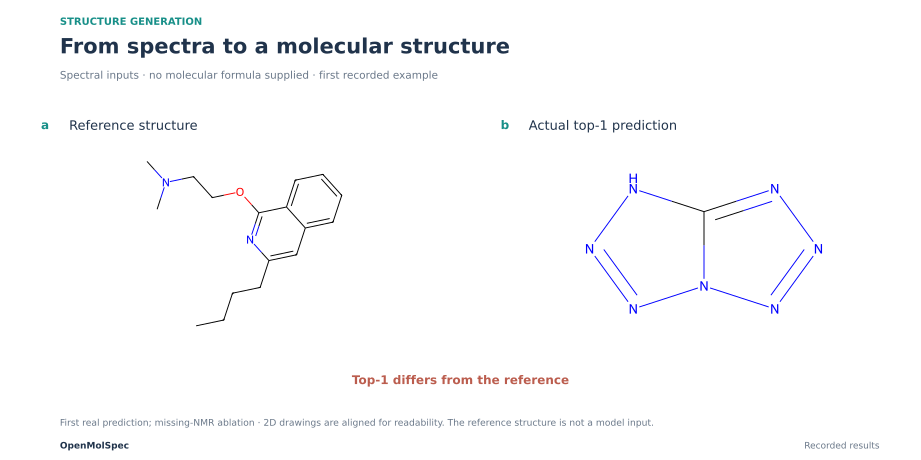

In [4]:
figure = render('vibrational.generation', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/vibrational-generation.md) · [Quick Start](../quickstart.md)
